In [1]:
import numpy as np
import matplotlib.pyplot as plt
from taia1dvfd.analysis import LotusData, get_model_variable, compute_forecast_score_uv

In [2]:
def _eps(exp_name: str, n_ens: int = 1000):
    obs = LotusData()
    ue_obs = obs.u + 1.j*obs.v
    z_model, t_model, ue_m, ue_v = get_model_variable(f"/home/mnex/Desktop/1DV_FD/experiments/0_tests/output/{exp_name}_ne{n_ens}.nc", "ue", cplx = True)
    return compute_forecast_score_uv(ue_m, ue_v, z_model, t_model, n_ens, ue_obs, obs.z, obs.n)    

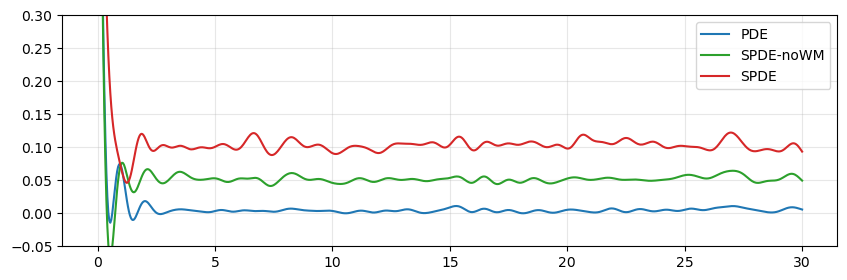

In [3]:
plt.figure(figsize = (10, 3))
plt.plot(*_eps('PDE'),       label = 'PDE',       color = 'C0')
plt.plot(*_eps('SPDE-noWM'), label = 'SPDE-noWM', color = 'C2')
plt.plot(*_eps('SPDE'),      label = 'SPDE',      color = 'C3')
plt.ylim(-0.05, 0.3)
plt.grid(alpha = 0.3)
plt.legend()

In [4]:
def _profile_uv(ax, exp_name: str, n_ens: int = 1000, label = None, color = None):
    z_model, t_model, ue_m, ue_v = get_model_variable(f"/home/mnex/Desktop/1DV_FD/experiments/0_tests/output/{exp_name}_ne{n_ens}.nc", "ue", cplx = True)
    
    # 20 days mean, skip the first 10
    idx_t = np.where(t_model/86400 >= 10)[0]
    uem = np.mean(ue_m[idx_t, :], axis = 0)
    uev = np.mean(ue_v[idx_t, :], axis = 0)

    # u-profile
    ax[0].plot(uem.real, z_model, label = label, color = color)
    ax[0].fill_betweenx(z_model, uem.real - uev.real**0.5, uem.real + uev.real**0.5, alpha = 0.1, color = color)

    # v-profile
    ax[1].plot(uem.imag, z_model, label = label, color = color)
    ax[1].fill_betweenx(z_model, uem.imag - uev.imag**0.5, uem.imag + uev.imag**0.5, alpha = 0.1, color = color)

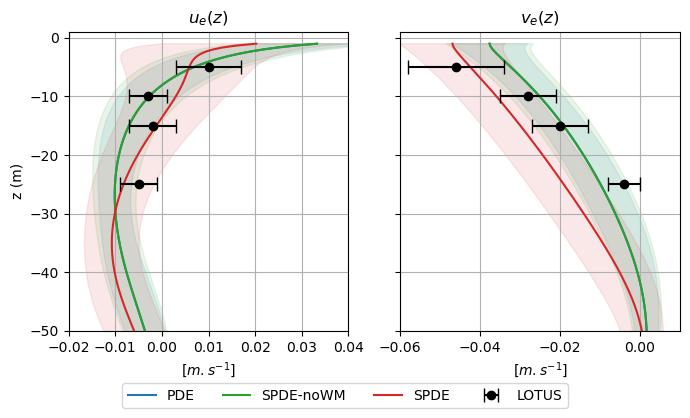

In [ ]:
fig, ax = plt.subplots(1, 2, figsize = (7, 4), sharey = True)

_profile_uv(ax, 'PDE',       label = 'PDE',       color = 'C0')
_profile_uv(ax, 'SPDE-noWM', label = 'SPDE-noWM', color = 'C2')
_profile_uv(ax, 'SPDE',      label = 'SPDE',      color = 'C3')

# --- LOTUS obs errorbar ---
obs = LotusData()
ax[0].errorbar(obs.u[0], obs.z, xerr = obs.DWC_std, color = 'k', ecolor = 'k', fmt = 'o', label = 'LOTUS', capsize=5)
ax[0].set_title(r'$u_e(z)$')
ax[0].set_xlabel(r'$[m.s^{-1}]$')
ax[0].set_ylabel('z (m)')
ax[0].set_xlim(-0.02, 0.04)
ax[0].set_ylim(-50, 1)
ax[0].grid()

ax[1].errorbar(obs.v[0], obs.z, xerr = obs.CWC_std, color = 'k', ecolor = 'k', fmt = 'o', label = 'LOTUS', capsize=5)
ax[1].set_title(r'$v_e(z)$')
ax[1].set_xlabel(r'$[m.s^{-1}]$')
ax[1].set_xlim(-0.06, 0.01)
ax[1].set_ylim(-50, 1)
ax[1].grid()

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=4)
fig.tight_layout()